# Taller 2 - Red de Monitoreo de Calidad del Aire de Bogota.
http://rmcab.ambientebogota.gov.co/Report/stationreport

## Descripción de los datos 

## 1. Cargar Librerias
***

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

## 2. Cargar Datos

In [2]:
df = pd.read_csv('data/dataset_with_geo_missing.csv', sep=",")
df.head()

,PM10,PM2.5,NO,NO2,NOX,CO,OZONO,Station,DateTime,Status,Latitud,Longitud,Localidad,Name,month,day_week,day_month,hour
0,56.6,32.7,7.504,15.962,23.493,0.44924,2.431,USM,2021-01-01 01:00:00,True,4.532097,-74.116947,Usme,usame,1.0,4.0,1.0,1.0
1,59.3,39.3,16.560,17.866,34.426,0.69832,1.121,USM,2021-01-01 02:00:00,True,4.532097,-74.116947,Usme,usame,1.0,4.0,1.0,2.0
2,96.4,70.8,22.989,17.802,40.791,0.88243,1.172,USM,2021-01-01 03:00:00,True,4.532097,-74.116947,Usme,usame,1.0,4.0,1.0,3.0
3,108.3,81.0,3.704,9.886,13.591,0.29549,6.565,USM,2021-01-01 04:00:00,True,4.532097,-74.116947,Usme,usame,1.0,4.0,1.0,4.0
4,87.7,56.1,2.098,9.272,11.371,0.16621,9.513,USM,2021-01-01 05:00:00,True,4.532097,-74.116947,Usme,usame,1.0,4.0,1.0,5.0


## 3: Explorar datos
*** 

###  3.1 Estadisticas 
***
Resumen: 
- Identificar nombre de las columnas
- Número de columnas y filas 
- Tamaño del conjunto de datos
- Tipos de datos
- Porcentajes de valores
- Correlaciones de variables
- Valores nulos


In [3]:
# Estadisticas basicas del conjunto de datos 
df.columns

Index(['PM10', 'PM2.5', 'NO', 'NO2', 'NOX', 'CO', 'OZONO', 'Station',
       'DateTime', 'Status', 'Latitud', 'Longitud', 'Localidad', 'Name',
       'month', 'day_week', 'day_month', 'hour'],
      dtype='object')

In [4]:
df.describe()


,PM10,PM2.5,NO,NO2,NOX,CO,OZONO,Latitud,Longitud,month,day_week,day_month,hour
count,146444.000000,151146.000000,138776.000000,138778.000000,138772.000000,135202.000000,134308.000000,166458.000000,166458.000000,166440.000000,166440.000000,166440.000000,166440.000000
mean,31.974816,15.322021,18.616861,14.979247,33.590300,0.691262,11.782188,4.653331,-74.104733,6.526027,3.002854,15.720548,12.500000
std,22.836232,12.467023,26.932382,9.233824,30.056319,0.574756,10.133101,0.068115,0.039154,3.447862,1.998034,8.796273,6.922207
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.532097,-74.166272,1.000000,0.000000,1.000000,1.000000
25%,15.800000,6.000000,3.169000,7.515000,13.109000,0.324902,3.458000,4.595958,-74.143714,4.000000,1.000000,8.000000,6.750000
50%,26.700000,12.000000,7.759000,13.742000,24.259000,0.520590,9.564000,4.645117,-74.114869,7.000000,3.000000,16.000000,12.500000
75%,42.300000,21.600000,21.532000,20.626000,43.472250,0.862208,17.518250,4.710381,-74.069472,10.000000,5.000000,23.000000,18.250000
max,326.200000,188.000000,341.104000,92.256000,361.341000,12.025010,88.182000,4.783614,-74.030414,12.000000,6.000000,31.000000,24.000000


In [5]:
df.shape

(166458, 18)

In [6]:
# Comprobar el número de Filas y Columnas 
print("Número de  Filas: ", len(df))
print("Número de Columnas ", + len(df.columns))

#Comprobar el tipo de datos en las características
print(df.dtypes)
df.info()


Número de  Filas:  166458
Número de Columnas  18
PM10         float64
PM2.5        float64
NO           float64
NO2          float64
NOX          float64
CO           float64
OZONO        float64
Station       object
DateTime      object
Status          bool
Latitud      float64
Longitud     float64
Localidad     object
Name          object
month        float64
day_week     float64
day_month    float64
hour         float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166458 entries, 0 to 166457
Data columns (total 18 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   PM10       146444 non-null  float64
 1   PM2.5      151146 non-null  float64
 2   NO         138776 non-null  float64
 3   NO2        138778 non-null  float64
 4   NOX        138772 non-null  float64
 5   CO         135202 non-null  float64
 6   OZONO      134308 non-null  float64
 7   Station    166458 non-null  object 
 8   DateTime   166440 non-null  objec

In [7]:
#Comprobar si hay valores nulos true o false
filas_con_nulos = df.isnull().any(axis=1).sum()
porcentaje_nulos = df.isnull().mean() * 100
print(f"Número de filas con datos nulos: {filas_con_nulos}")
print(f"Porcetajes de nulos:")
print(porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False))
df.isnull()

Número de filas con datos nulos: 74821
Porcetajes de nulos:
OZONO        19.314181
CO           18.777109
NOX          16.632424
NO           16.630021
NO2          16.628819
PM10         12.023453
PM2.5         9.198717
DateTime      0.010814
month         0.010814
day_week      0.010814
day_month     0.010814
hour          0.010814
dtype: float64


,PM10,PM2.5,NO,NO2,NOX,CO,OZONO,Station,DateTime,Status,Latitud,Longitud,Localidad,Name,month,day_week,day_month,hour
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166453,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
166454,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
166455,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
166456,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [8]:
df.dropna(subset=['DateTime'], inplace=True) #Eliminar filas sin fecha y asegurar formato
df['DateTime'] = pd.to_datetime(df['DateTime']) # Aseguramos que sea fecha

df = df.sort_values('DateTime') # se ordena segun el tiempo

target = 'PM2.5'
df.dropna(subset=[target], inplace=True)

#Rellenar huecos pequeños en los predictores
predictores = ['OZONO', 'CO', 'NOX', 'NO', 'NO2', 'PM10']
df[predictores] = df[predictores].interpolate(method='linear', limit=3)

df.dropna(inplace=True) #borrar  filas restantes para que el modelo no falle

# Verificación
print("Cantidad de nulos restantes:")
print(df.isnull().sum())
print(f"\nTamaño final del dataset para entrenar: {df.shape}")

Cantidad de nulos restantes:
PM10         0
PM2.5        0
NO           0
NO2          0
NOX          0
CO           0
OZONO        0
Station      0
DateTime     0
Status       0
Latitud      0
Longitud     0
Localidad    0
Name         0
month        0
day_week     0
day_month    0
hour         0
dtype: int64

Tamaño final del dataset para entrenar: (150976, 18)


In [9]:
# Resumen de una variable (False V.S. True) en la variable Status
Status_Summary = df.groupby('Status').mean(numeric_only=True)
Status_Summary

,PM10,PM2.5,NO,NO2,NOX,CO,OZONO,Latitud,Longitud,month,day_week,day_month,hour
Status,,,,,,,,,,,,,
False,19.158628,6.079135,12.312487,11.732229,24.044817,0.480809,12.165923,4.656004,-74.097674,6.455613,3.024700,15.545629,12.557965
True,45.105683,24.623640,25.508123,18.688545,44.192702,0.897457,11.254329,4.647201,-74.113797,6.886604,2.996785,16.003109,12.431132


In [10]:
#Filtrar datos por columnas 
#df['Status'] = df[target]>12
df['Status'] = df['OZONO']>12
df.Status.value_counts()

Status
False    88925
True     62051
Name: count, dtype: int64

####  3.1.1 Correlación
***

Resumen:


- Hay una correlación **positiva(+) a 1** o **negativa(-) a -1** hay una correlacion fuerte. La aproximación a 0 es mas debil la relacion lineal  

,PM10,PM2.5,NO,NO2,NOX,CO,OZONO,Status,Latitud,Longitud,month,day_week,day_month,hour
PM10,1.000000,0.777385,0.294861,0.369189,0.377328,0.485732,-0.018392,-0.066876,-0.147141,-0.328267,0.071588,-0.045368,0.023964,0.001765
PM2.5,0.777385,1.000000,0.302912,0.427607,0.402422,0.533434,-0.036136,-0.090474,-0.112899,-0.250192,0.056602,-0.021607,0.025062,-0.017245
NO,0.294861,0.302912,1.000000,0.189030,0.953024,0.434351,-0.298721,-0.263897,0.000561,0.097988,0.069104,-0.040722,0.015012,-0.092157
NO2,0.369189,0.427607,0.189030,1.000000,0.475007,0.418174,-0.299775,-0.330382,-0.048454,-0.242687,0.124962,-0.059963,0.040544,0.078943
NOX,0.377328,0.402422,0.953024,0.475007,1.000000,0.517208,-0.359355,-0.337518,-0.014500,0.013478,0.100112,-0.054822,0.026056,-0.058393
CO,0.485732,0.533434,0.434351,0.418174,0.517208,1.000000,-0.268880,-0.264027,-0.209976,-0.189708,0.029136,-0.032391,0.013974,0.067236
OZONO,-0.018392,-0.036136,-0.298721,-0.299775,-0.359355,-0.268880,1.000000,0.802390,0.002515,0.046283,-0.053024,0.033614,-0.004673,0.140046
Status,-0.066876,-0.090474,-0.263897,-0.330382,-0.337518,-0.264027,0.802390,1.000000,0.000105,0.065821,-0.051690,0.028863,-0.004631,0.126379
Latitud,-0.147141,-0.112899,0.000561,-0.048454,-0.014500,-0.209976,0.002515,0.000105,1.000000,0.454741,0.027045,0.001252,0.005815,0.000588
Longitud,-0.328267,-0.250192,0.097988,-0.242687,0.013478,-0.189708,0.046283,0.065821,0.454741,1.000000,0.011097,-0.001122,0.000451,0.000672


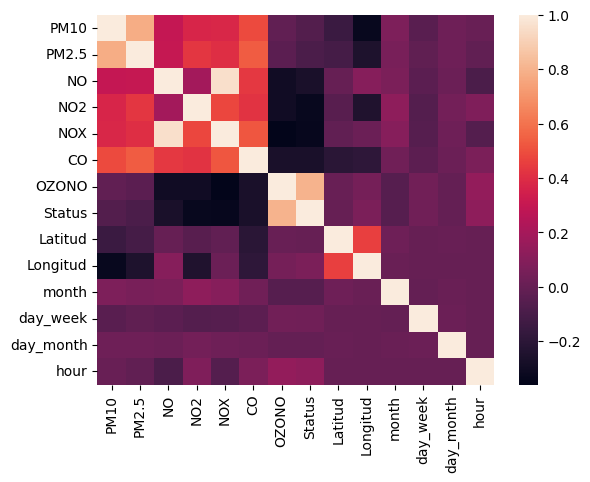

In [11]:
#Matriz de correlación
corr = df.corr(numeric_only=True)
corr = (corr)
sns.heatmap(corr, 
            xticklabels=corr.columns.values,
            yticklabels=corr.columns.values)
corr



###  3.2 Gráficos de distribución 


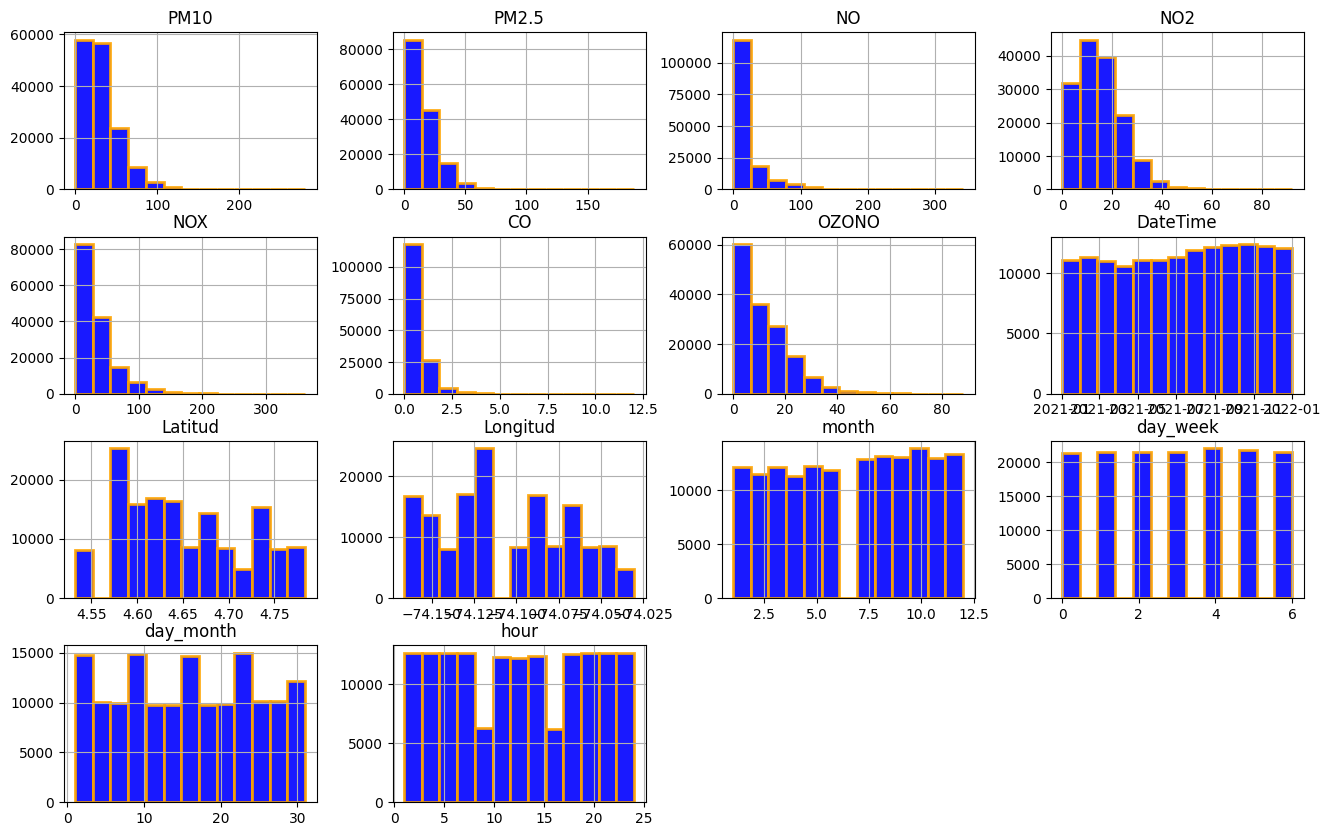

In [12]:
#hist es un grafico (pandas) de distribucion de  datos.
#este grafico nos sirve para identificar cuales son las variables numericas y su frencuencia. 

df.hist(figsize=(16,10),facecolor='blue', alpha=0.9, bins=13, edgecolor='orange', linewidth=2)
plt.show()

/var/folders/mk/dnyv3qdx2jv5qxqdq2h915j00000gp/T/ipykernel_57158/1448057234.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df.PM10, kde=False, color="g", ax=axes[0]).set_title('PM10')
/var/folders/mk/dnyv3qdx2jv5qxqdq2h915j00000gp/T/ipykernel_57158/1448057234.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe

Text(0.5, 1.0, 'NOX')

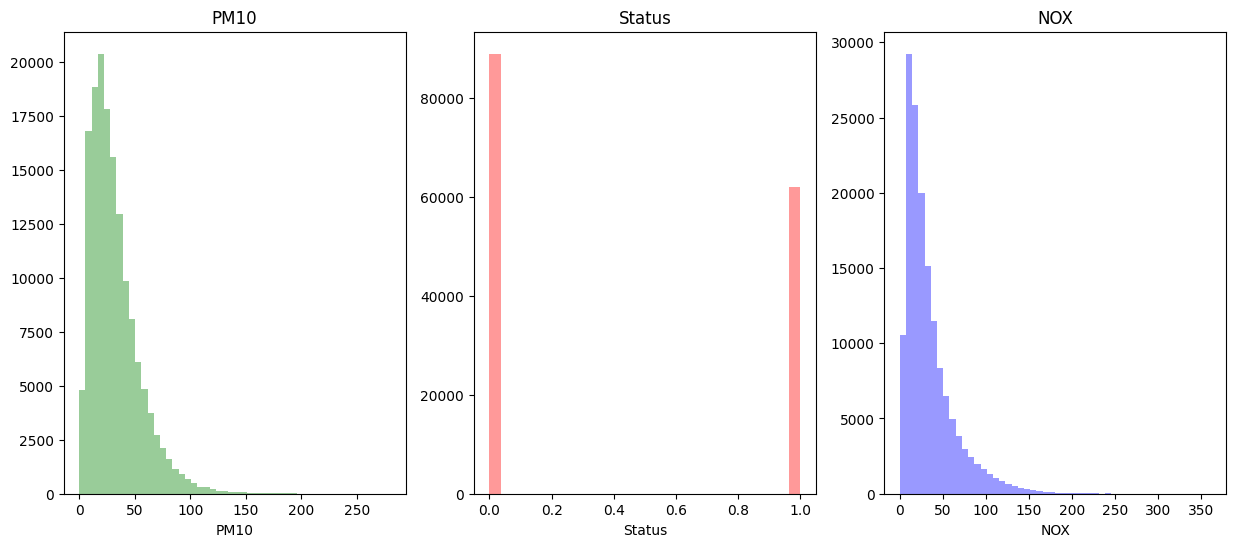

In [13]:
#otra forma de ver la distribucion de los datos
# Uso de Libreria Seaborn (sna) para poner multiples graficos de distribución  
f, axes = plt.subplots(ncols=3, figsize=(15, 6))

#variable PM10
sns.distplot(df.PM10, kde=False, color="g", ax=axes[0]).set_title('PM10')

#variable PM10
sns.distplot(df.Status, kde=False, color="r", ax=axes[1]).set_title('Status')

#variable NOX
sns.distplot(df.NOX, kde=False, color="b", ax=axes[2]).set_title('NOX')

###  3.3 Gráfico de barras


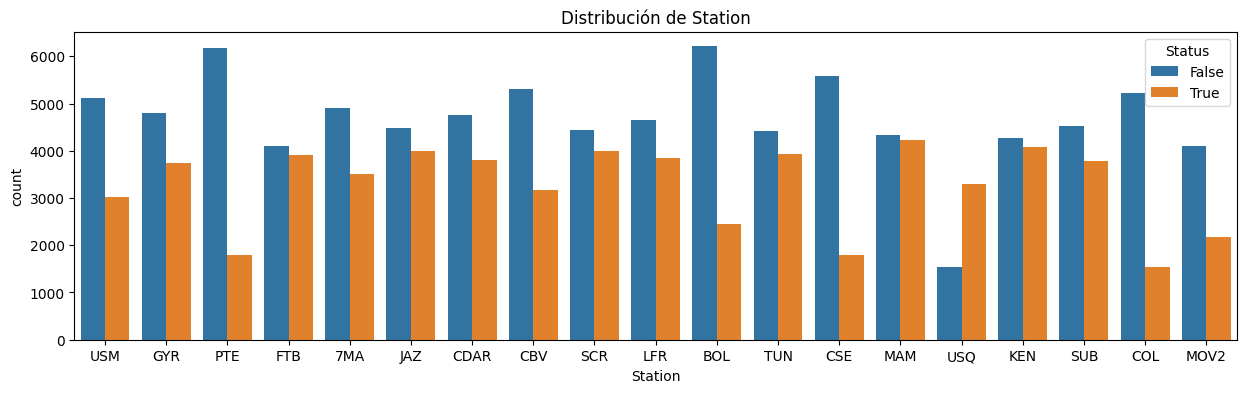

In [14]:
#ditribucion por estacion 
f, ax = plt.subplots(figsize=(15, 4))
sns.countplot(x="Station", hue='Status', data=df).set_title('Distribución de Station');

(array([    0.,  2000.,  4000.,  6000.,  8000., 10000.]),
 [Text(0.0, 0, '0'),
  Text(2000.0, 0, '2000'),
  Text(4000.0, 0, '4000'),
  Text(6000.0, 0, '6000'),
  Text(8000.0, 0, '8000'),
  Text(10000.0, 0, '10000')])

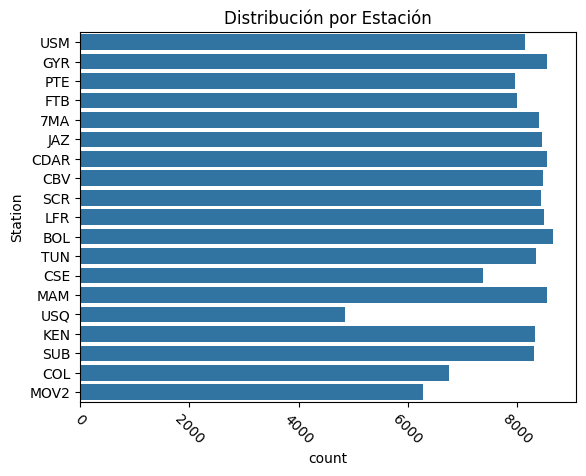

In [15]:
# Types of colors
color_types = ['#78C850','#F08030','#6890F0','#A8B820','#A8A878','#A040A0','#F8D030',  
                '#E0C068','#EE99AC','#C03028','#F85888','#B8A038','#705898','#98D8D8','#7038F8' ,'#FFFFF']

# Count Plot (a.k.a. Bar Plot)
sns.countplot(y='Station', data=df).set_title('Distribución por Estación');
 
# Rotate x-labels
plt.xticks(rotation=-45)

###  3.4 Gráficos de Cajas


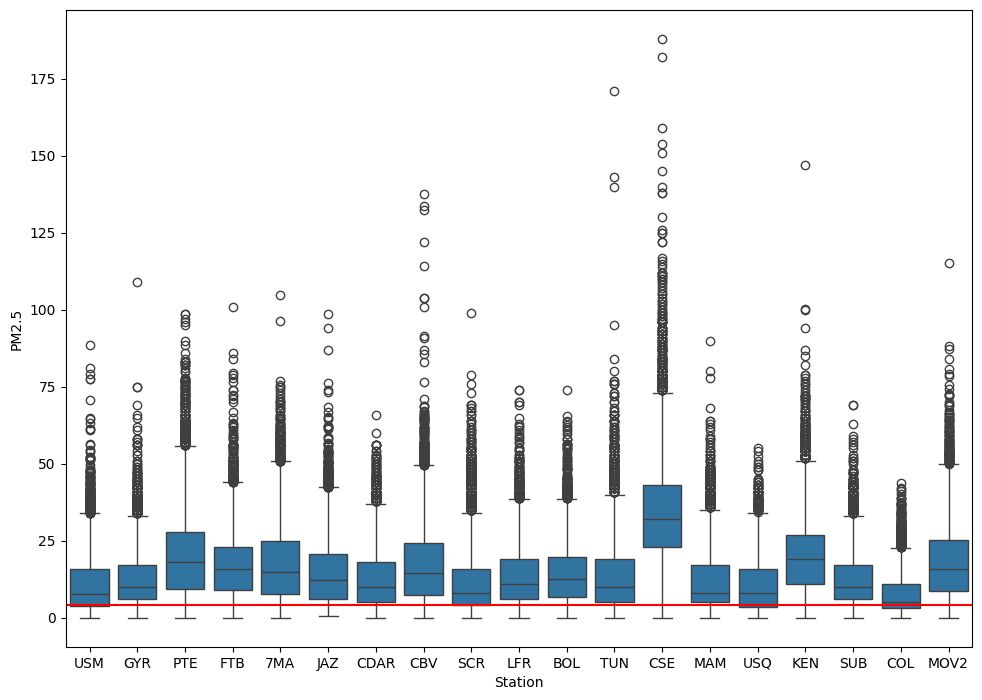

In [16]:
import seaborn as sns

a4_dims = (11.7, 8.27)
fig, ax = plt.subplots(figsize=a4_dims)

sns.boxplot(x="Station", y="PM2.5",  data=df)
valh=4
plt.axhline(valh, color='red')

Hemos revisado la información de ded dataset "calidad del aire", donde es importante la estación que mide la calidad del aire, sin embargo, no tenemos donde esta ubicada. 

Ahora vamos a cargar un nuevo dataset, que contiene la infromación de la ubicación (Latitud, Longitud) de cada estación.

## 4. Tecnicas para solucionar valores perdidos y anomalias en un dataset

In [17]:
#Contar valores nulos por columnas
df.isnull().sum()

PM10         0
PM2.5        0
NO           0
NO2          0
NOX          0
CO           0
OZONO        0
Station      0
DateTime     0
Status       0
Latitud      0
Longitud     0
Localidad    0
Name         0
month        0
day_week     0
day_month    0
hour         0
dtype: int64

### 4.1 Completar con la media, mediana o desviación estándar

In [18]:
df_1 = df.copy()

# Calculamos la mediana solo de las columnas numéricas
valores_mediana = df.median(numeric_only=True)

# Rellenamos los huecos (NaN) con esos valores calculados
df_1 = df_1.fillna(valores_mediana)

print("Nulos restantes por columna:")
print(df_1.isnull().sum())

# Miremos cómo quedó una fila de ejemplo (la primera)
print("\nPrimera fila rellenada:")
print(df_1.iloc[0])

Nulos restantes por columna:
PM10         0
PM2.5        0
NO           0
NO2          0
NOX          0
CO           0
OZONO        0
Station      0
DateTime     0
Status       0
Latitud      0
Longitud     0
Localidad    0
Name         0
month        0
day_week     0
day_month    0
hour         0
dtype: int64

Primera fila rellenada:
PM10                        56.6
PM2.5                       32.7
NO                         7.504
NO2                       15.962
NOX                       23.493
CO                       0.44924
OZONO                      2.431
Station                      USM
DateTime     2021-01-01 01:00:00
Status                     False
Latitud                 4.532097
Longitud              -74.116947
Localidad                   Usme
Name                       usame
month                        1.0
day_week                     4.0
day_month                    1.0
hour                         1.0
Name: 0, dtype: object


In [19]:
df_1.isnull().sum()

PM10         0
PM2.5        0
NO           0
NO2          0
NOX          0
CO           0
OZONO        0
Station      0
DateTime     0
Status       0
Latitud      0
Longitud     0
Localidad    0
Name         0
month        0
day_week     0
day_month    0
hour         0
dtype: int64

### 4.2 Completar con valor predeterminada 

In [20]:
df_2 = df.fillna(25)
df_2.iloc[0]

PM10                        56.6
PM2.5                       32.7
NO                         7.504
NO2                       15.962
NOX                       23.493
CO                       0.44924
OZONO                      2.431
Station                      USM
DateTime     2021-01-01 01:00:00
Status                     False
Latitud                 4.532097
Longitud              -74.116947
Localidad                   Usme
Name                       usame
month                        1.0
day_week                     4.0
day_month                    1.0
hour                         1.0
Name: 0, dtype: object

In [21]:
df_2.isnull().sum()

PM10         0
PM2.5        0
NO           0
NO2          0
NOX          0
CO           0
OZONO        0
Station      0
DateTime     0
Status       0
Latitud      0
Longitud     0
Localidad    0
Name         0
month        0
day_week     0
day_month    0
hour         0
dtype: int64

### 4.3 Eliminar NaN

In [22]:
# Elimina todas las filas del DataFrame original 'df' que tengan al menos un NaN
df_3 = df.dropna()

# Verificamos la diferencia de tamaño
print(f"Filas originales: {df.shape[0]}")
print(f"Filas limpias (df_3): {df_3.shape[0]}")
print(f"Filas eliminadas: {df.shape[0] - df_3.shape[0]}")

Filas originales: 150976
Filas limpias (df_3): 150976
Filas eliminadas: 0


In [23]:
df_3.isnull().sum()

PM10         0
PM2.5        0
NO           0
NO2          0
NOX          0
CO           0
OZONO        0
Station      0
DateTime     0
Status       0
Latitud      0
Longitud     0
Localidad    0
Name         0
month        0
day_week     0
day_month    0
hour         0
dtype: int64

In [24]:

cols_to_filter = ['PM2.5', 'PM10', 'OZONO']
df_final = df_3.copy()

print(f"Filas antes de filtrar outliers: {len(df_final)}")

for col in cols_to_filter:
    Q1 = df_final[col].quantile(0.25)
    Q3 = df_final[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # Definir límites (1.5 veces el rango intercuartílico es estándar)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Filtrar
    df_final = df_final[(df_final[col] >= lower_bound) & (df_final[col] <= upper_bound)]

print(f"Filas después de filtrar outliers: {len(df_final)}")

df_final.to_csv('data/dataset_limpio_calidad_aire.csv', index=False)

print("\n¡Éxito! El archivo 'dataset_limpio_calidad_aire.csv' ha sido creado.")

Filas antes de filtrar outliers: 150976
Filas después de filtrar outliers: 140375

¡Éxito! El archivo 'dataset_limpio_calidad_aire.csv' ha sido creado.
